> **ANEXO – Hipótesis inicial (solo variables de la ficha).** Documenta el primer planteamiento del equipo: predecir la alteración nutricional usando únicamente las variables administrativas de la ficha nominal. El resultado fue negativo (`Anexo_Step6_solo_ficha`) y **justificó el enfoque con mediciones** de los Steps 4–6. Se conserva como evidencia del proceso.

# **Anexo Step 4 – Reducción y proyección (solo ficha)**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 4:* «Data reduction and projection: finding useful features to represent the data. Using methods to reduce the number of variables.»

Entrada: `datos/2_limpios/step3_ninos_anexo.csv` (un registro por niño, sin imputar).
Salidas: `datos/3_transformados/anexo4_train.csv`, `anexo4_test.csv` (sin transformar) y `anexo4_decisiones.json` (columnas descartadas). Las transformaciones se ajustan aquí para analizarlas y se vuelven a ajustar **dentro de cada pliegue** en el Anexo Step 6.

**Convenciones:** la partición se hace **primero**; imputadores, escaladores y codificadores se ajustan **solo con entrenamiento** y se aplican con `transform` a prueba.

## Librerías y rutas

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
LIM, OUT = Path("../datos/2_limpios"), Path("../datos/3_transformados")
RES, FIG = Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
SEED = 2026

## 1. Lectura de la tabla por niño

In [2]:
ninos = pd.read_csv(LIM/"step3_ninos_anexo.csv", sep="|", encoding="utf-8").set_index("id_nna")
assert ninos.index.is_unique
print("Tabla por niño:", ninos.shape)
print("Etiqueta estricta:", ninos["alteracion_estricta"].value_counts().to_dict(), "| amplia:", ninos["alteracion"].value_counts().to_dict())

Tabla por niño: (150, 27)
Etiqueta estricta: {0: 90, 1: 60} | amplia: {1: 102, 0: 48}


## 2. Definición de variables

| Grupo | Variables | Tratamiento |
|---|---|---|
| Numéricas continuas | `edad`, `tiempo_hogar_meses` | Imputación KNN (tiempo) + estandarización **robusta** |
| Ordinales | `severidad_discapacidad` (0–3), `nivel_educativo` (Ninguno < Inicial < Primaria < Secundaria < Técnico) | Codificación ordinal; severidad imputada con la mediana |
| Binarias | `sexo`, `estudia`, `nacido_en_lima`, `anemia`, `otra_condicion_salud`, 4 indicadores de soporte, `salud_mental_especializada`, `atencion_psicologica` | 0/1 |
| Nominales | `situacion_legal`, `upe`, `estado_pti`, `tipo_ie` | *One-hot* (`drop='first'`) |

**Se excluyen de los predictores:** `nutri_componentes` y la otra etiqueta (derivadas del objetivo: fuga directa); `tiene_discapacidad` y `n_tipos_soporte` (redundantes); `ingreso_imputado`, `n_registros_dx`, `periodo_ref` (metadatos del proceso).

Se arma la matriz de predictores candidatos.

In [3]:
orden_edu = {"Ninguno":0, "Inicial":1, "Primaria":2, "Secundaria":3, "Técnico":4}
X = pd.DataFrame(index=ninos.index)
X["edad"], X["tiempo_hogar_meses"] = ninos["edad"], ninos["tiempo_hogar_meses"]
X["sexo_M"] = (ninos["sexo"] == "M").astype(int)
X["nivel_educativo_ord"] = ninos["nivel_educativo"].map(orden_edu)
X["severidad_discapacidad"] = ninos["severidad_discapacidad"]
bin_cols = ["estudia","nacido_en_lima","anemia","otra_condicion_salud","soporte_acompanamiento","soporte_psicoterapia",
            "soporte_estimulacion","soporte_taller","salud_mental_especializada","atencion_psicologica"]
nominales = ["situacion_legal","upe","estado_pti","tipo_ie"]
X[bin_cols] = ninos[bin_cols]; X[nominales] = ninos[nominales]
Y = ninos[["alteracion_estricta","alteracion"]]
print("Predictores candidatos:", X.shape[1], "| vacíos:", X.isna().sum()[X.isna().sum() > 0].to_dict())

Predictores candidatos: 19 | vacíos: {'tiempo_hogar_meses': 4}


## 3. Partición entrenamiento / prueba (antes de transformar)
Cada fila es un niño distinto, así que una partición aleatoria no mezcla niños entre conjuntos. Se estratifica por la **etiqueta estricta** (principal) y se usa 75 % / 25 % con semilla fija.

In [4]:
idx_tr, idx_te = train_test_split(X.index, test_size=0.25, stratify=Y["alteracion_estricta"], random_state=SEED)
Xtr, Xte, Ytr, Yte = X.loc[idx_tr], X.loc[idx_te], Y.loc[idx_tr], Y.loc[idx_te]
print("Train:", Xtr.shape, "| Test:", Xte.shape)
for t in Y.columns: print(f"% positivos {t}: total {100*Y[t].mean():.1f} | train {100*Ytr[t].mean():.1f} | test {100*Yte[t].mean():.1f}")

Train: (112, 19) | Test: (38, 19)
% positivos alteracion_estricta: total 40.0 | train 40.2 | test 39.5
% positivos alteracion: total 68.0 | train 68.8 | test 65.8


## 4. Imputación (ajustada en entrenamiento)
- `tiempo_hogar_meses`: los vacíos vienen de fechas de ingreso mal digitadas (Step 3), que no dependen del estado nutricional → **MCAR**. Se imputa con **KNN (k = 5)** sobre edad y tiempo, que conserva la relación edad–tiempo mejor que la media global.
- `severidad_discapacidad`: si faltara, se imputa con la **mediana** entre los niños con discapacidad del entrenamiento.

In [5]:
print("Vacíos antes: train", Xtr.isna().sum().sum(), "| test", Xte.isna().sum().sum())
knn = KNNImputer(n_neighbors=5).fit(Xtr[["edad","tiempo_hogar_meses"]])
med_sev = Xtr.loc[Xtr["severidad_discapacidad"] > 0, "severidad_discapacidad"].median()
def imputar(d):
    d = d.copy(); d[["edad","tiempo_hogar_meses"]] = knn.transform(d[["edad","tiempo_hogar_meses"]])
    d["severidad_discapacidad"] = d["severidad_discapacidad"].fillna(med_sev); return d
Xtr_i, Xte_i = imputar(Xtr), imputar(Xte)
print("Vacíos después: train", Xtr_i.isna().sum().sum(), "| test", Xte_i.isna().sum().sum(), "| mediana de severidad usada:", med_sev)

Vacíos antes: train 1 | test 3
Vacíos después: train 0 | test 0 | mediana de severidad usada: 1.5


## 5. Análisis bivariado con la etiqueta (solo entrenamiento)
Se miden diferencias entre niños con y sin alteración estricta. **Es exploratorio**: muestra pequeña y muchas pruebas a la vez, así que los *p*-valores no son conclusiones.

In [6]:
y_tr = Ytr["alteracion_estricta"]; filas = []
for c in ["edad","tiempo_hogar_meses","severidad_discapacidad","nivel_educativo_ord"]:
    a, b = Xtr_i.loc[y_tr==1, c], Xtr_i.loc[y_tr==0, c]
    filas.append({"variable": c, "tipo": "numérica", "con alteración": f"mediana {a.median():.1f}", "sin alteración": f"mediana {b.median():.1f}",
                  "p-valor": round(stats.mannwhitneyu(a, b).pvalue, 3)})
for c in ["sexo_M"] + bin_cols + nominales:
    t = pd.crosstab(Xtr_i[c], y_tr)
    if t.shape[0] < 2: filas.append({"variable": c, "tipo": "categórica", "con alteración": "constante en train", "sin alteración": "", "p-valor": np.nan}); continue
    desc = " | ".join(f"{k}: {100*t.loc[k,1]/t.loc[k].sum():.0f}%" for k in t.index)
    filas.append({"variable": c, "tipo": "categórica", "con alteración": desc, "sin alteración": "(% con alteración por categoría)", "p-valor": round(stats.chi2_contingency(t)[1], 3)})
biv = pd.DataFrame(filas).sort_values("p-valor"); pd.set_option("display.max_colwidth", 110); biv

,variable,tipo,con alteración,sin alteración,p-valor
0,edad,numérica,mediana 12.4,mediana 9.3,0.028
3,nivel_educativo_ord,numérica,mediana 2.0,mediana 2.0,0.035
12,soporte_taller,categórica,0: 36% | 1: 61%,(% con alteración por categoría),0.086
5,estudia,categórica,0: 14% | 1: 42%,(% con alteración por categoría),0.296
18,tipo_ie,categórica,CEBE (especial): 50% | EBA (alternativa): 50% | EBR: 41% | Ninguna: 0% | Técnica/taller: 100%,(% con alteración por categoría),0.352
16,upe,categórica,Lima: 30% | Lima Este: 47% | Lima Norte-Callao: 46% | Lima Sur: 29% | Otra: 0%,(% con alteración por categoría),0.370
4,sexo_M,categórica,0: 35% | 1: 44%,(% con alteración por categoría),0.395
17,estado_pti,categórica,Actual: 39% | No tiene: 50% | Vencido: 35%,(% con alteración por categoría),0.508
15,situacion_legal,categórica,Definitiva: 44% | Otra: 0% | Provisional: 42% | Urgente: 22%,(% con alteración por categoría),0.553
1,tiempo_hogar_meses,numérica,mediana 63.8,mediana 57.9,0.650


**Interpretación.** Con la etiqueta estricta, la única diferencia clara es la **edad** (mediana 12,4 frente a 9,3 años; *p* = 0,028), y el nivel educativo, que la acompaña (*p* = 0,035). El resto de variables administrativas no muestra diferencias (todos los *p* > 0,08): situación legal, UPE, PTI, soporte psicoemocional o discapacidad se reparten de forma parecida entre niños con y sin alteración. `otra_condicion_salud` es constante en train. Esto anticipa que las variables de la ficha **aportarán poco más allá de la edad**, lo que se comprueba en el Anexo Step 6.

## 6. Transformaciones
### 6.1 Estandarización: ¿estándar o robusta?
`tiempo_hogar_meses` tiene asimetría positiva y casos de larga estancia (hasta ≈332 meses). La estandarización clásica (media y desviación) se deja arrastrar por los extremos; la robusta (mediana y RIC) no. Se comparan antes de decidir.

Asimetría: {'edad': -0.0, 'tiempo_hogar_meses': 0.75}
Valor máximo tras escalar: {'edad_std': 1.85, 'edad_rob': 1.25, 'tiempo_hogar_meses_std': 2.85, 'tiempo_hogar_meses_rob': 1.9}


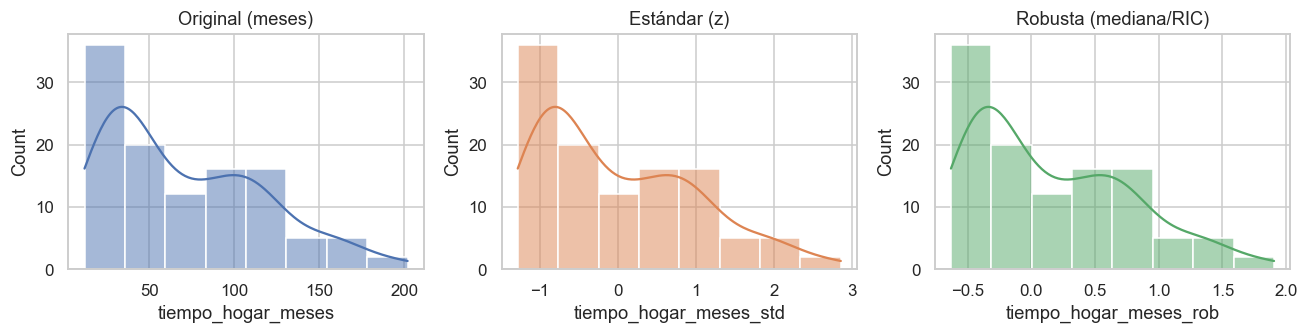

In [7]:
comp = pd.DataFrame(index=Xtr_i.index)
for c in ["edad","tiempo_hogar_meses"]:
    comp[c+"_std"] = StandardScaler().fit_transform(Xtr_i[[c]]).ravel(); comp[c+"_rob"] = RobustScaler().fit_transform(Xtr_i[[c]]).ravel()
asim = Xtr_i[["edad","tiempo_hogar_meses"]].skew().round(2).to_dict(); print("Asimetría:", asim)
print("Valor máximo tras escalar:", comp.max().round(2).to_dict())
fig, axs = plt.subplots(1, 3, figsize=(12,3.2))
sns.histplot(Xtr_i["tiempo_hogar_meses"], kde=True, ax=axs[0], color="#4C72B0").set_title("Original (meses)")
sns.histplot(comp["tiempo_hogar_meses_std"], kde=True, ax=axs[1], color="#DD8452").set_title("Estándar (z)")
sns.histplot(comp["tiempo_hogar_meses_rob"], kde=True, ax=axs[2], color="#55A868").set_title("Robusta (mediana/RIC)")
plt.tight_layout(); plt.savefig(FIG/"anexo4_escalado_tiempo.png", bbox_inches="tight"); plt.show()

**Decisión.** Se usa `RobustScaler` para las dos continuas. En este entrenamiento la diferencia es moderada (máximo de 1,9 RIC frente a 2,85 desviaciones en el tiempo en el hogar), pero el caso de mayor estancia (≈332 meses) quedó en **prueba**: la escala robusta, al no depender de la media ni de la desviación, es más estable ante extremos en datos nuevos. No se confunde *estandarizar* con *normalizar*: no se fuerza ningún rango fijo.

### 6.2 Codificación (ajustada en entrenamiento)
Escalado robusto de las continuas y *one-hot* de las nominales, ajustados en train y aplicados a test.

In [8]:
num_cols = ["edad","tiempo_hogar_meses"]
ct = ColumnTransformer([("num", RobustScaler(), num_cols),
                        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), nominales)],
                       remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
Ztr = ct.fit_transform(Xtr_i); Zte = ct.transform(Xte_i)
print("Train:", Ztr.shape, "| Test:", Zte.shape, "| sin vacíos:", int(Ztr.isna().sum().sum() + Zte.isna().sum().sum()) == 0)
print("Columnas one-hot:", [c for c in Ztr.columns if any(c.startswith(n+"_") for n in nominales)])
print("Mediana en train (≈0):", Ztr[num_cols].median().round(2).to_dict(), "| en test:", Zte[num_cols].median().round(2).to_dict())

Train: (112, 28) | Test: (38, 28) | sin vacíos: True
Columnas one-hot: ['situacion_legal_Otra', 'situacion_legal_Provisional', 'situacion_legal_Urgente', 'upe_Lima Este', 'upe_Lima Norte-Callao', 'upe_Lima Sur', 'upe_Otra', 'estado_pti_No tiene', 'estado_pti_Vencido', 'tipo_ie_EBA (alternativa)', 'tipo_ie_EBR', 'tipo_ie_Ninguna', 'tipo_ie_Técnica/taller']
Mediana en train (≈0): {'edad': 0.0, 'tiempo_hogar_meses': 0.0} | en test: {'edad': 0.03, 'tiempo_hogar_meses': 0.07}


## 7. Reducción de variables
### 7.1 Variables casi constantes
Una columna que casi nunca vale 1 no permite aprender nada fiable con ≈110 niños. Se descartan las binarias con menos del 5 % de unos (o de ceros) en entrenamiento.

In [9]:
bin_like = [c for c in Ztr.columns if c not in num_cols and set(Ztr[c].unique()) <= {0, 1}]
prev = Ztr[bin_like].mean()
raras = prev[(prev < 0.05) | (prev > 0.95)]
print("Descartadas por casi constantes:", raras.round(3).to_dict())
n0 = Ztr.shape[1]; Ztr, Zte = Ztr.drop(columns=raras.index), Zte.drop(columns=raras.index)
print("Columnas: antes", n0, "-> después", Ztr.shape[1])

Descartadas por casi constantes: {'situacion_legal_Otra': 0.009, 'upe_Otra': 0.018, 'tipo_ie_EBA (alternativa)': 0.018, 'tipo_ie_Ninguna': 0.036, 'tipo_ie_Técnica/taller': 0.009, 'anemia': 0.009, 'otra_condicion_salud': 0.0, 'soporte_estimulacion': 0.036, 'atencion_psicologica': 0.018}
Columnas: antes 28 -> después 19


**Interpretación.** Se descartan 9 columnas: **`anemia` (0,9 %) y `otra_condicion_salud` (0 %)** casi no aparecen en el último registro de los niños de entrenamiento, `atencion_psicologica` y `soporte_estimulacion` son raras, y las categorías poco frecuentes de `situacion_legal`, `upe` y `tipo_ie` (< 5 %) se eliminan como columnas, de modo que esos niños quedan en la categoría de referencia.

### 7.2 Correlaciones entre predictores
Se busca información duplicada (|r| alto) que inestabilice los modelos lineales (Spearman, solo train).

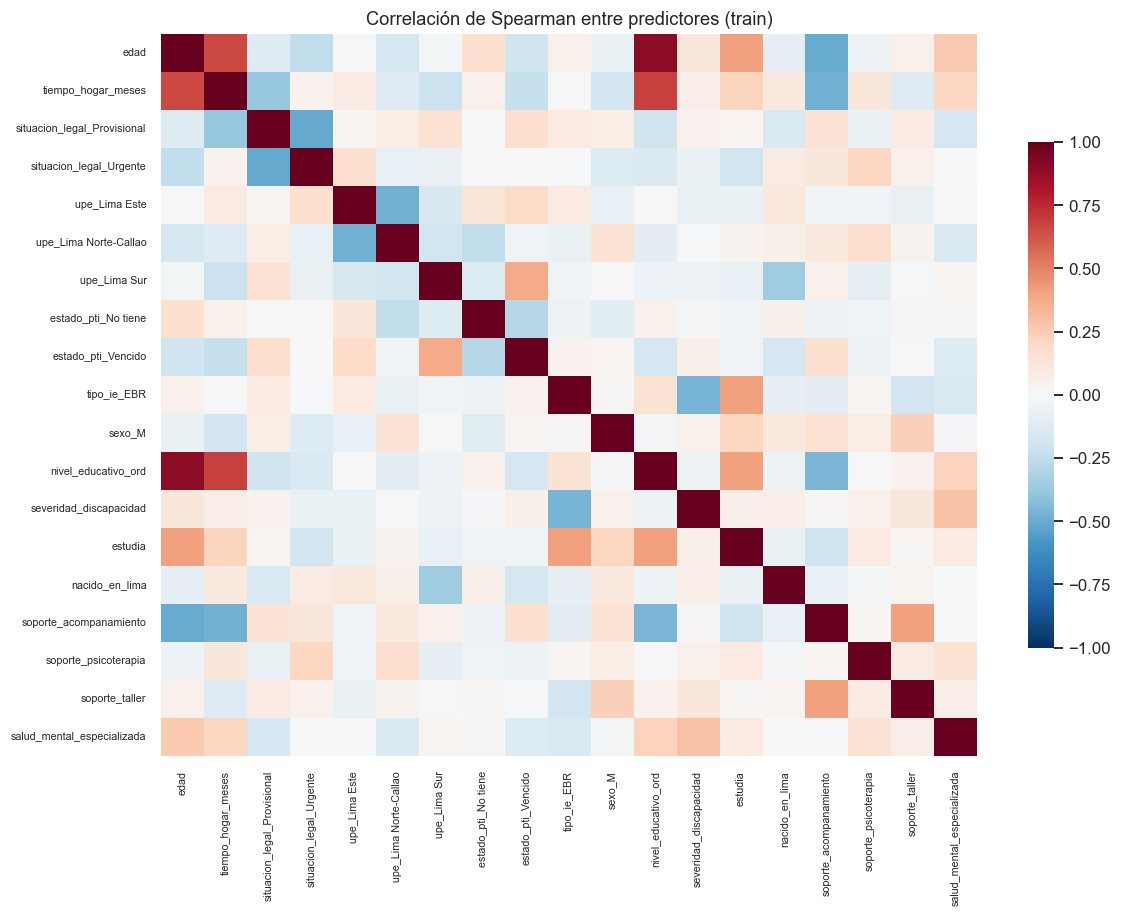

,var1,var2,r
10,edad,nivel_educativo_ord,0.89


In [10]:
corr = Ztr.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11,8.5))
sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="RdBu_r", ax=ax, cbar_kws={"shrink":.7}, xticklabels=True, yticklabels=True)
ax.tick_params(labelsize=7); ax.set_title("Correlación de Spearman entre predictores (train)")
plt.tight_layout(); plt.savefig(FIG/"anexo4_correlaciones.png", bbox_inches="tight"); plt.show()
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("r").reset_index().rename(columns={"level_0":"var1","level_1":"var2"})
pares = pares[pares["r"].abs() >= 0.7].sort_values("r", key=abs, ascending=False); pares.round(2)

**Interpretación.** Solo un par supera |r| ≥ 0,7: `edad` y `nivel_educativo_ord` (r = 0,89), porque a mayor edad, mayor nivel educativo logrado.

Se aplica la regla: con |r| ≥ 0,85 se conserva la variable más fina e interpretable.

In [11]:
alta = pares[pares["r"].abs() >= 0.85]
quitar_corr = ["nivel_educativo_ord"] if ((alta["var1"] == "edad") & (alta["var2"] == "nivel_educativo_ord")).any() or ((alta["var2"] == "edad") & (alta["var1"] == "nivel_educativo_ord")).any() else []
print("Pares con |r| >= 0,85:", alta.round(2).values.tolist(), "| se quita:", quitar_corr)
Ztr, Zte = Ztr.drop(columns=quitar_corr), Zte.drop(columns=quitar_corr)
print("Columnas finales:", Ztr.shape[1])

Pares con |r| >= 0,85: [['edad', 'nivel_educativo_ord', 0.89]] | se quita: ['nivel_educativo_ord']
Columnas finales: 18


### 7.3 Componentes principales (exploratorio)
Se evalúa si un PCA resumiría los predictores en pocos componentes (todas las columnas estandarizadas, solo train).

Variables: 18 | componentes para 80 % de varianza: 10 | autovalor > 1 (Kaiser): 7


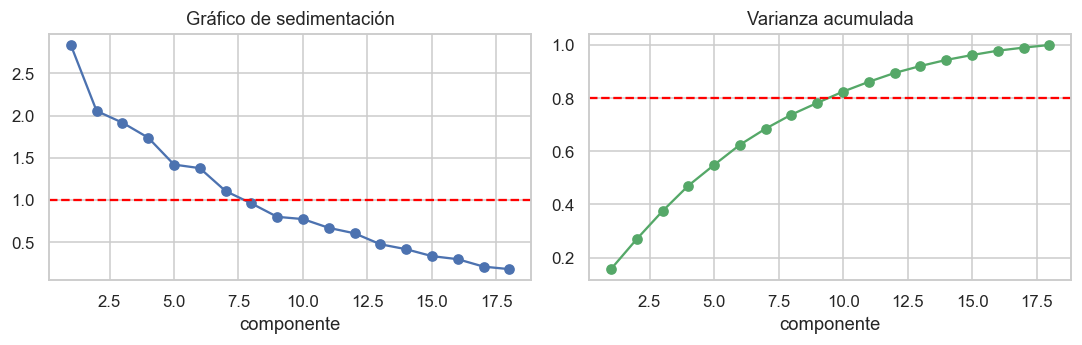

In [12]:
pca = PCA().fit(StandardScaler().fit_transform(Ztr))
var = pca.explained_variance_ratio_; acum = var.cumsum()
k80 = int(np.argmax(acum >= 0.80)) + 1; kaiser = int((pca.explained_variance_ > 1).sum())
print(f"Variables: {Ztr.shape[1]} | componentes para 80 % de varianza: {k80} | autovalor > 1 (Kaiser): {kaiser}")
fig, axs = plt.subplots(1, 2, figsize=(10,3.3))
axs[0].plot(range(1, len(var)+1), pca.explained_variance_, "o-"); axs[0].axhline(1, color="red", ls="--"); axs[0].set_title("Gráfico de sedimentación"); axs[0].set_xlabel("componente")
axs[1].plot(range(1, len(var)+1), acum, "o-", color="#55A868"); axs[1].axhline(.8, color="red", ls="--"); axs[1].set_title("Varianza acumulada"); axs[1].set_xlabel("componente")
plt.tight_layout(); plt.savefig(FIG/"anexo4_pca.png", bbox_inches="tight"); plt.show()

**Interpretación.** No hay pocos factores dominantes: hacen falta **10 componentes para el 80 %** de la varianza (7 con autovalor > 1) de 18 variables. El ahorro es pequeño y se perdería interpretabilidad, que importa porque cada variable es una situación concreta del niño. **Decisión: no se usa PCA**; la reducción se hace por selección de variables (§7.1 y §7.2).

## 8. Guardado
Se guardan los conjuntos **sin transformar** (para que el Anexo Step 6 ajuste imputación y codificación dentro de cada pliegue) y las decisiones de reducción.

In [13]:
Xtr.join(Ytr).to_csv(OUT/"anexo4_train.csv", sep="|", encoding="utf-8")
Xte.join(Yte).to_csv(OUT/"anexo4_test.csv", sep="|", encoding="utf-8")
decisiones = {"semilla": SEED, "num_cols": num_cols, "nominales": nominales, "orden_educativo": orden_edu,
              "descartar_tras_codificar": list(raras.index) + quitar_corr, "columnas_finales": list(Ztr.columns)}
json.dump(decisiones, open(OUT/"anexo4_decisiones.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
print("Train:", Xtr.shape, "| Test:", Xte.shape, "| columnas finales tras codificar:", len(decisiones["columnas_finales"]))

Train: (112, 19) | Test: (38, 19) | columnas finales tras codificar: 18


## 9. Reporte

| Paso | Antes → después | Justificación |
|---|---|---|
| Predictores candidatos | 27 columnas → 19 | Se excluyen las derivadas del objetivo y las redundantes |
| Partición estratificada (etiqueta estricta) | 150 niños → 112 train / 38 test | Antes de ajustar cualquier transformación |
| Imputación | 4 vacíos de tiempo en el hogar (1 train, 3 test) | KNN ajustado en train; MCAR por error de digitación |
| Estandarización robusta | `edad`, `tiempo_hogar_meses` | Asimetría y caso extremo de larga estancia |
| Codificación | 19 → 28 columnas | *One-hot* (`drop='first'`) de 4 nominales |
| Casi constantes | 28 → 19 | 9 columnas con menos del 5 % de unos o de ceros |
| Correlación alta | 19 → 18 | `nivel_educativo_ord` repite a la edad (r = 0,89) |
| PCA | no se usa | 10 de 18 componentes para el 80 % |
| Desbalance | sin remuestreo | Ponderación de clases dentro de la validación cruzada |

## Verificación y cifras de este notebook

In [14]:
assert ninos.shape[0] == 150 and Xtr.shape == (112, 19) and Xte.shape == (38, 19)
assert biv.set_index("variable").loc["edad", "p-valor"] == 0.028
assert len(raras) == 9 and quitar_corr == ["nivel_educativo_ord"] and Ztr.shape[1] == 18 and (k80, kaiser) == (10, 7)
assert Xte["tiempo_hogar_meses"].max() > 330
cifras = {"ninos": 150, "ninos_train": len(Xtr), "ninos_test": len(Xte), "predictores_finales": Ztr.shape[1], "pca_k80": k80}
json.dump(cifras, open(RES/"cifras_anexo4.json", "w"), indent=1); cifras

{'ninos': 150,
 'ninos_train': 112,
 'ninos_test': 38,
 'predictores_finales': 18,
 'pca_k80': 10}

## Declaración de uso de IA
Se usó **Claude Code (Anthropic)** para reorganizar el Anexo anterior, mover la imputación después de la partición (ajustada solo en train) y guardar los datos sin transformar para validarlos con `Pipeline`. El equipo revisó las decisiones contra las tablas impresas y los `assert` de la celda anterior.

Siguiente: `Anexo_Step6_solo_ficha.ipynb`.